# 02. Análisis Exploratorio de Datos (EDA) — IBM TabFormer
**Unidad 1:** Detección de Fraude en Transacciones con Tarjeta de Crédito  
**Dataset:** IBM TabFormer (`card_transaction.v1.csv`)  
**Entorno:** Python 3.12 | Polars | Matplotlib | Seaborn

---

### Objetivos del Notebook:
1. Analizar las dimensiones, tipos de datos y consistencia del dataset con Polars.
2. Cuantificar el desbalance severo de la variable objetivo `Is Fraud?`.
3. Evaluar los valores ausentes por columna y entender su significado de negocio (`Errors?`, `Zip`, `Merchant State`).
4. Investigar la distribución de importes (`Amount`), identificando y explicando importes negativos (devoluciones).
5. Analizar modalidades de pago (`Use Chip`) y categorías comerciales (`MCC`) en relación con el riesgo de fraude.
6. Estudiar la dinámica temporal (años 1991–2020 y patrones horarios intradía).
7. Documentar hallazgos, limitaciones y decisiones que fundamentarán el preprocesamiento.


In [1]:
import sys
from pathlib import Path

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR
while not (PROJECT_ROOT / "notebooks").exists() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from notebooks._comun.config import RAW_DATA_FILE, TARGET_COL
from notebooks._comun.data_utils import scan_dataset, clean_amount_expr, categorize_mcc_expr
print(f"Raíz del proyecto: {PROJECT_ROOT}")


Raíz del proyecto: /home/glender/ProyectosUNi/iaupeu


In [2]:
import polars as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

lf = scan_dataset(RAW_DATA_FILE)
print("LazyFrame inicializado correctamente.")


LazyFrame inicializado correctamente.


## 1. Dimensiones y Esquema de Columnas
Examinamos el volumen total de transacciones y los tipos inferidos.


In [3]:
total_rows = lf.select(pl.len()).collect().item()
schema = lf.collect_schema()

print(f"Dimensiones del dataset: {total_rows:,} filas x {len(schema)} columnas")

cols_summary = pl.DataFrame({
    "Columna": list(schema.names()),
    "Tipo": [str(t) for t in schema.values()]
})
print(cols_summary)


Dimensiones del dataset: 24,386,900 filas x 15 columnas
shape: (15, 2)
┌────────────────┬─────────┐
│ Columna        ┆ Tipo    │
│ ---            ┆ ---     │
│ str            ┆ str     │
╞════════════════╪═════════╡
│ User           ┆ Int64   │
│ Card           ┆ Int64   │
│ Year           ┆ Int64   │
│ Month          ┆ Int64   │
│ Day            ┆ Int64   │
│ …              ┆ …       │
│ Merchant State ┆ String  │
│ Zip            ┆ Float64 │
│ MCC            ┆ Int64   │
│ Errors?        ┆ String  │
│ Is Fraud?      ┆ String  │
└────────────────┴─────────┘


## 2. Distribución de la Variable Objetivo (`Is Fraud?`)
Analizamos el grado de desbalance entre transacciones legítimas (`No`) y fraudulentas (`Yes`).


Distribución de Clases:
shape: (2, 3)
┌───────────┬──────────┬────────────┐
│ Is Fraud? ┆ count    ┆ percentage │
│ ---       ┆ ---      ┆ ---        │
│ str       ┆ u32      ┆ f64        │
╞═══════════╪══════════╪════════════╡
│ No        ┆ 24357143 ┆ 99.878     │
│ Yes       ┆ 29757    ┆ 0.122      │
└───────────┴──────────┴────────────┘


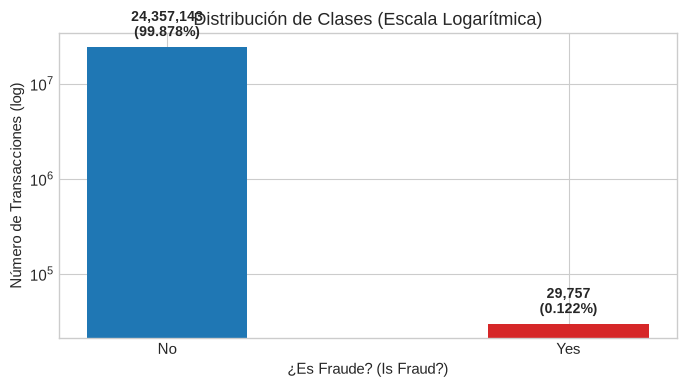

In [4]:
fraud_dist = (
    lf.group_by("Is Fraud?")
    .agg(pl.len().alias("count"))
    .with_columns((pl.col("count") / total_rows * 100).round(4).alias("percentage"))
    .sort("count", descending=True)
    .collect()
)

print("Distribución de Clases:")
print(fraud_dist)

# Gráfico de barras del desbalance
fig, ax = plt.subplots(figsize=(7, 4))
df_plot = fraud_dist.to_pandas()
bars = ax.bar(df_plot["Is Fraud?"], df_plot["count"], color=["#1f77b4", "#d62728"], width=0.4)
ax.set_yscale("log")
ax.set_title("Distribución de Clases (Escala Logarítmica)")
ax.set_ylabel("Número de Transacciones (log)")
ax.set_xlabel("¿Es Fraude? (Is Fraud?)")

for bar, pct in zip(bars, df_plot["percentage"]):
    height = bar.get_height()
    ax.annotate(f"{height:,}\n({pct:.3f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()


> **Interpretación para Detección de Fraude:**
> - El dataset presenta **29,757 fraudes** sobre un total de **24,386,900 transacciones**, lo que representa una prevalencia de apenas **0.122%** (aproximadamente 1 fraude por cada 820 operaciones).
> - Este desbalance extremo confirma que la métrica tradicional de **Accuracy es completamente engañosa**: un clasificador trivial que predijera siempre "No fraude" alcanzaría un 99.878% de precisión aparente sin detectar ninguna amenaza real.
> - El diseño de modelos debe priorizar métricas enfocadas en la clase minoritaria como **PR-AUC (Average Precision)**, **Recall** y **F1-Score**.


## 3. Análisis de Valores Faltantes (Nulos)
Inspeccionamos el porcentaje de valores ausentes en todas las columnas para comprender su origen transaccional.


Porcentaje de Valores Nulos por Columna:
shape: (15, 2)
┌────────────────┬───────────┐
│ Columna        ┆ Pct_Nulos │
│ ---            ┆ ---       │
│ str            ┆ f64       │
╞════════════════╪═══════════╡
│ Errors?        ┆ 98.407    │
│ Zip            ┆ 11.802    │
│ Merchant State ┆ 11.157    │
│ User           ┆ 0.0       │
│ Card           ┆ 0.0       │
│ …              ┆ …         │
│ Use Chip       ┆ 0.0       │
│ Merchant Name  ┆ 0.0       │
│ Merchant City  ┆ 0.0       │
│ MCC            ┆ 0.0       │
│ Is Fraud?      ┆ 0.0       │
└────────────────┴───────────┘


/tmp/ipykernel_206470/1500901509.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=significant_nulls, x="Pct_Nulos", y="Columna", palette="Blues_r", ax=ax)


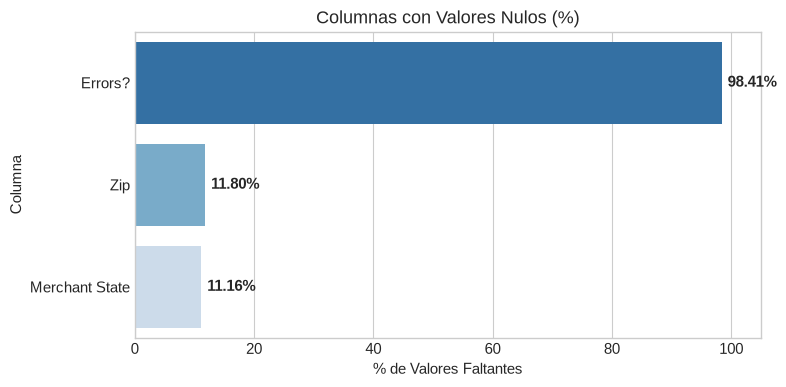

In [5]:
null_exprs = [
    (pl.col(c).null_count() / total_rows * 100).round(3).alias(c)
    for c in schema.names()
]

null_df = (
    lf.select(null_exprs)
    .collect()
    .transpose(include_header=True, header_name="Columna", column_names=["Pct_Nulos"])
    .sort("Pct_Nulos", descending=True)
)

print("Porcentaje de Valores Nulos por Columna:")
print(null_df)

# Visualización de nulos significativos
significant_nulls = null_df.filter(pl.col("Pct_Nulos") > 0).to_pandas()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=significant_nulls, x="Pct_Nulos", y="Columna", palette="Blues_r", ax=ax)
ax.set_title("Columnas con Valores Nulos (%)")
ax.set_xlabel("% de Valores Faltantes")
ax.set_xlim(0, 105)
for i, v in enumerate(significant_nulls["Pct_Nulos"]):
    ax.text(v + 1, i, f"{v:.2f}%", va="center", fontweight="bold")
plt.tight_layout()
plt.show()


> **Interpretación de Valores Faltantes:**
> 1. `Errors?` tiene un **98.4% de nulos**: Esto es coherente con el negocio bancario, ya que la gran mayoría de transacciones se aprueban sin errores técnicos o de validación. Sin embargo, dado que este campo describe fallos post-ingreso (como `Bad PIN` o `Insufficient Balance`), su inclusión como predictor previo a la decisión introduce un severo riesgo de **fuga de datos (Target Leakage)**.
> 2. `Zip` (11.8%) y `Merchant State` (11.2%): Los valores ausentes coinciden primordialmente con transacciones en línea (`Online Transaction`) o comercios internacionales donde no existe código postal ni estado estadounidense registrado. Deben ser imputados con categorías semánticas como `"ONLINE"` o `"MISSING"`.


## 4. Distribución de Importes (`Amount`) y Análisis de Devoluciones
Sanitizamos la columna de texto eliminando el símbolo de divisa `$` y evaluamos su distribución estadística.


In [6]:
amt_expr = clean_amount_expr("Amount")

amt_stats = lf.select([
    amt_expr.min().alias("min"),
    amt_expr.quantile(0.25).alias("q25"),
    amt_expr.median().alias("mediana"),
    amt_expr.mean().alias("media"),
    amt_expr.quantile(0.75).alias("q75"),
    amt_expr.quantile(0.99).alias("q99"),
    amt_expr.max().alias("max"),
    (amt_expr < 0).sum().alias("conteo_negativos"),
    ((amt_expr < 0).sum() / total_rows * 100).round(3).alias("pct_negativos"),
]).collect()

print("Estadísticas Globales de Importe ($):")
print(amt_stats)

# Comparación estadística entre Legítimas y Fraude
amt_by_fraud = (
    lf.with_columns(amt_expr.alias("Amount_Num"))
    .group_by("Is Fraud?")
    .agg([
        pl.len().alias("count"),
        pl.col("Amount_Num").min().alias("min"),
        pl.col("Amount_Num").median().alias("mediana"),
        pl.col("Amount_Num").mean().round(2).alias("media"),
        pl.col("Amount_Num").quantile(0.95).round(2).alias("q95"),
        pl.col("Amount_Num").max().alias("max"),
        (pl.col("Amount_Num") < 0).sum().alias("negativos"),
    ])
    .collect()
)

print("\nComparación de Importes por Clase:")
print(amt_by_fraud)


Estadísticas Globales de Importe ($):
shape: (1, 9)
┌────────┬─────┬─────────┬───────────┬───┬────────┬─────────┬──────────────────┬───────────────┐
│ min    ┆ q25 ┆ mediana ┆ media     ┆ … ┆ q99    ┆ max     ┆ conteo_negativos ┆ pct_negativos │
│ ---    ┆ --- ┆ ---     ┆ ---       ┆   ┆ ---    ┆ ---     ┆ ---              ┆ ---           │
│ f64    ┆ f64 ┆ f64     ┆ f64       ┆   ┆ f64    ┆ f64     ┆ u32              ┆ f64           │
╞════════╪═════╪═════════╪═══════════╪═══╪════════╪═════════╪══════════════════╪═══════════════╡
│ -500.0 ┆ 9.2 ┆ 30.14   ┆ 43.634005 ┆ … ┆ 316.99 ┆ 12390.5 ┆ 1244683          ┆ 5.104         │
└────────┴─────┴─────────┴───────────┴───┴────────┴─────────┴──────────────────┴───────────────┘



Comparación de Importes por Clase:
shape: (2, 8)
┌───────────┬──────────┬────────┬─────────┬────────┬────────┬─────────┬───────────┐
│ Is Fraud? ┆ count    ┆ min    ┆ mediana ┆ media  ┆ q95    ┆ max     ┆ negativos │
│ ---       ┆ ---      ┆ ---    ┆ ---     ┆ ---    ┆ ---    ┆ ---     ┆ ---       │
│ str       ┆ u32      ┆ f64    ┆ f64     ┆ f64    ┆ f64    ┆ f64     ┆ u32       │
╞═══════════╪══════════╪════════╪═════════╪════════╪════════╪═════════╪═══════════╡
│ No        ┆ 24357143 ┆ -500.0 ┆ 30.11   ┆ 43.55  ┆ 146.43 ┆ 12390.5 ┆ 1243558   │
│ Yes       ┆ 29757    ┆ -500.0 ┆ 71.02   ┆ 108.59 ┆ 398.27 ┆ 5694.44 ┆ 1125      │
└───────────┴──────────┴────────┴─────────┴────────┴────────┴─────────┴───────────┘


> **Hallazgo Crítico sobre Importes:**
> - Se identifican **1,244,683 transacciones con importes negativos** (mínimo -500.00), equivalentes al **5.1%** del dataset.
> - En la operativa de tarjetas de crédito, los importes negativos corresponden a **abonos, devoluciones de compra y reembolsos por aclaraciones**.
> - Notablemente, en el subconjunto de transacciones marcadas como fraude (`Is Fraud? == Yes`), **ninguna transacción tiene importe negativo** (conteo de negativos = 0). El fraude se concentra en cargos no autorizados de compra.
> - **Decisión para el preprocesamiento:** Para el modelado de detección de compras fraudulentas, las transacciones negativas deben ser filtradas o tratadas como una población operativa distinta, evitando distorsionar los estimadores estadísticos de compra.


## 5. Modalidades de Pago (`Use Chip`) y Tasa de Fraude
Evaluamos el riesgo según la tecnología del canal de pago: banda magnética (`Swipe`), chip de contacto (`Chip`) o comercio electrónico (`Online`).


Riesgo por Modalidad de Pago:
shape: (3, 5)
┌────────────────────┬──────────┬─────────┬─────────────┬─────────────────┐
│ Use Chip           ┆ total    ┆ fraudes ┆ pct_volumen ┆ tasa_fraude_pct │
│ ---                ┆ ---      ┆ ---     ┆ ---         ┆ ---             │
│ str                ┆ u32      ┆ u32     ┆ f64         ┆ f64             │
╞════════════════════╪══════════╪═════════╪═════════════╪═════════════════╡
│ Online Transaction ┆ 2713220  ┆ 18349   ┆ 11.13       ┆ 0.6763          │
│ Chip Transaction   ┆ 6287598  ┆ 4836    ┆ 25.78       ┆ 0.0769          │
│ Swipe Transaction  ┆ 15386082 ┆ 6572    ┆ 63.09       ┆ 0.0427          │
└────────────────────┴──────────┴─────────┴─────────────┴─────────────────┘


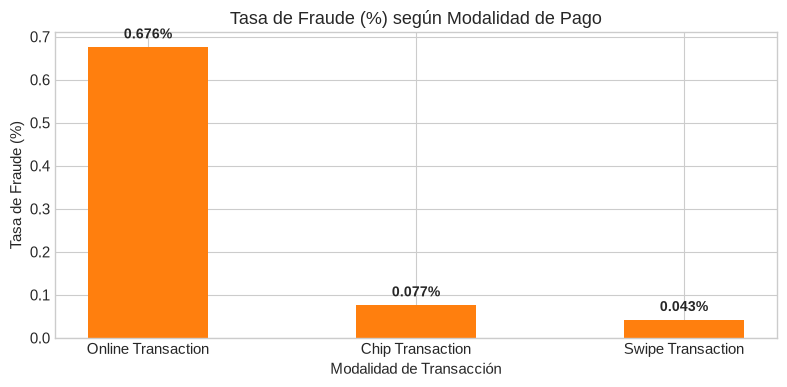

In [7]:
chip_summary = (
    lf.group_by("Use Chip")
    .agg([
        pl.len().alias("total"),
        (pl.col("Is Fraud?") == "Yes").sum().alias("fraudes"),
    ])
    .with_columns([
        (pl.col("total") / total_rows * 100).round(2).alias("pct_volumen"),
        (pl.col("fraudes") / pl.col("total") * 100).round(4).alias("tasa_fraude_pct"),
    ])
    .sort("tasa_fraude_pct", descending=True)
    .collect()
)

print("Riesgo por Modalidad de Pago:")
print(chip_summary)

# Gráfico de barras de tasa de fraude por modalidad
fig, ax = plt.subplots(figsize=(8, 4))
df_chip = chip_summary.to_pandas()
bars = ax.bar(df_chip["Use Chip"], df_chip["tasa_fraude_pct"], color="#ff7f0e", width=0.45)
ax.set_title("Tasa de Fraude (%) según Modalidad de Pago")
ax.set_ylabel("Tasa de Fraude (%)")
ax.set_xlabel("Modalidad de Transacción")

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.3f}%",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()


> **Interpretación:**
> - Las transacciones en línea (`Online Transaction`) presentan la mayor tasa de fraude porcentual, seguidas de operaciones por banda magnética (`Swipe Transaction`).
> - La modalidad `Use Chip` es un predictor categórico fundamental para el modelo de clasificación.


## 6. Dinámica Temporal: Tendencia Anual y Patrones Horarios
Analizamos la evolución histórica de 1991 a 2020 y el comportamiento horario intradía.


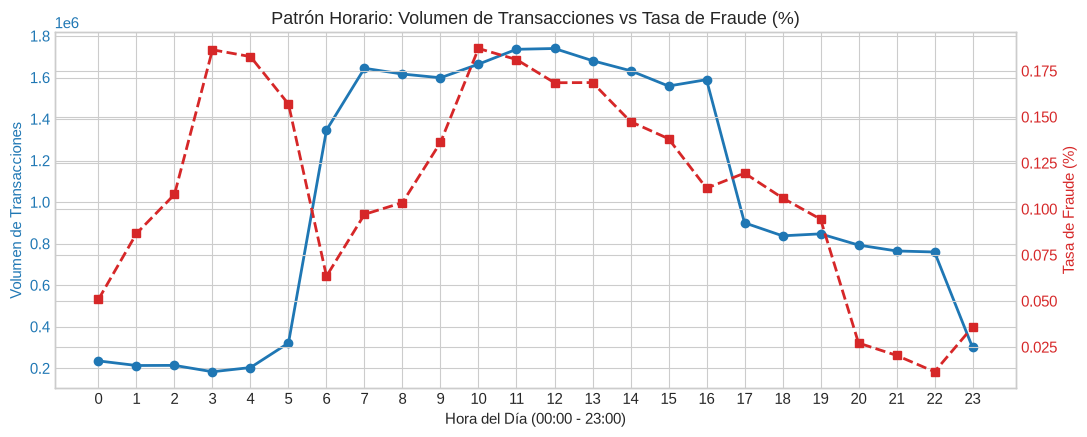

In [8]:
# Extracción de hora a partir de 'Time'
time_split = pl.col("Time").str.split(":")
hour_expr = time_split.list.get(0).cast(pl.Int32).alias("hour")

hourly_stats = (
    lf.with_columns(hour_expr)
    .group_by("hour")
    .agg([
        pl.len().alias("total"),
        (pl.col("Is Fraud?") == "Yes").sum().alias("fraudes"),
    ])
    .with_columns(
        (pl.col("fraudes") / pl.col("total") * 100).round(4).alias("tasa_fraude_pct")
    )
    .sort("hour")
    .collect()
)

# Gráfico horario
fig, ax1 = plt.subplots(figsize=(11, 4.5))
df_hour = hourly_stats.to_pandas()

color = "#1f77b4"
ax1.set_xlabel("Hora del Día (00:00 - 23:00)")
ax1.set_ylabel("Volumen de Transacciones", color=color)
ax1.plot(df_hour["hour"], df_hour["total"], marker="o", color=color, linewidth=2, label="Volumen Total")
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "#d62728"
ax2.set_ylabel("Tasa de Fraude (%)", color=color)
ax2.plot(df_hour["hour"], df_hour["tasa_fraude_pct"], marker="s", color=color, linewidth=2, linestyle="--", label="Tasa Fraude %")
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Patrón Horario: Volumen de Transacciones vs Tasa de Fraude (%)")
plt.xticks(range(0, 24))
fig.tight_layout()
plt.show()


> **Interpretación Temporal:**
> - Durante las horas de la madrugada (especialmente entre las **01:00 y las 05:00 horas**), el volumen total de transacciones desciende notablemente, pero la **tasa de fraude alcanza su pico más alto**.
> - Este comportamiento es típico del fraude automatizado y de transacciones no autorizadas mientras el titular legítimo duerme.
> - La hora (`hour`) y el indicador binario `is_night` constituyen variables predictoras de alto valor discriminante.


## 7. Síntesis de Hallazgos y Decisiones para Preprocesamiento

| Aspecto Analizado | Hallazgo Empírico | Decisión Metodológica para Preprocesamiento |
|---|---|---|
| **Desbalance Objetivo** | Prevalencia de 0.122% (29,757 fraudes en 24.38M filas). | Usar `class_weight='balanced'` en Regresión Logística y evaluar con PR-AUC y F1-Score en lugar de Accuracy. |
| **Importes Negativos** | 1,244,683 transacciones negativas (devoluciones). Cero fraudes en importes negativos. | Excluir transacciones de reembolso para modelar riesgo de compras/cargos no autorizados. |
| **Columna `Errors?`** | 98.4% nulos; describe fallos generados durante o post-liquidación. | Excluir del baseline para evitar fuga de datos (Data Leakage) hacia el modelo. |
| **Canal `Use Chip`** | Mayor riesgo relativo en `Online Transaction` y `Swipe`. | Codificar mediante One-Hot Encoding en el pipeline de scikit-learn. |
| **Componente Temporal** | Picos de fraude en horarios nocturnos (01:00 a 05:00). | Extraer `hour`, `minute`, `day_of_week` y construir indicador de nocturnidad `is_night`. |
| **Identificadores** | `User`, `Card`, `Merchant Name` son códigos arbitrarios de alta cardinalidad. | No utilizarlos como variables numéricas continuas para evitar memorización espuria. |
